In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../../data/data_final.csv")

diagnosis_variables = []

with open("../../../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])


train_index, test_index = next(cv)
x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

In [6]:
# Load best hyperparameters from repeated CV results
from sksurv.svm import FastSurvivalSVM
from sklearn.preprocessing import StandardScaler

best_results = pd.read_csv("../../../results/repeated_sub/ssvm_sub.csv")
best_params = best_results.iloc[0]  # Row 0 - best performing model

print("="*70)
print("BEST HYPERPARAMETERS FROM REPEATED CV")
print("="*70)
print(f"  alpha: {best_params['alpha']}")
print(f"  rank_ratio: {best_params['rank_ratio']}")
print(f"  tol: {best_params['tol']}")
print(f"  max_iter: {int(best_params['max_iter'])}")
print(f"  n_controls_per_case: {int(best_params['n_controls_per_case'])}")
print(f"  c-index-ipcw_mean (CV): {best_params['c-index-ipcw_mean']:.4f}")
print("="*70)

BEST HYPERPARAMETERS FROM REPEATED CV
  alpha: 0.01
  rank_ratio: 1.0
  tol: 0.001
  max_iter: 5000
  n_controls_per_case: 1
  c-index-ipcw_mean (CV): 0.7292


In [7]:
# 4-fold CV for feature importance extraction
sgkf_inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Storage for feature importances from each fold
all_fold_feature_importances = []

print("\n" + "="*70)
print("4-FOLD CV FEATURE IMPORTANCE EXTRACTION")
print("="*70)

for fold_idx, (train_index, val_index) in enumerate(sgkf_inner.split(X=x_train, y=subsampling['Regional LN recurrence'])):
    print(f"\n--- Fold {fold_idx + 1}/4 ---")
    
    # Get train and validation data
    x_train_fold = x_train.iloc[train_index]
    y_train_fold = y_train[train_index]
    x_val = x_train.iloc[val_index]
    y_val = y_train[val_index]
    train_fold_df = subsampling.iloc[train_index].copy()
    
    print(f"  Training samples (this fold): {len(x_train_fold)}")
    print(f"  Validation samples: {len(x_val)}")
    print(f"  Training events: {y_train_fold['event'].sum()}")
    print(f"  Validation events: {y_val['event'].sum()}")
    
    # Apply case-control subsampling to this fold's training data
    x_train_sub, y_train_sub, sub_dataset = sample_case_control(
        train_fold=train_fold_df,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_controls_per_case=int(best_params['n_controls_per_case']),
        feature_columns=feature_columns,
        random_state=12
    )
    print(f"  Subsampled training samples: {len(x_train_sub)}")
    
    # Scale features (required for SVM)
    scaler = StandardScaler()
    x_train_sub_scaled = scaler.fit_transform(x_train_sub)
    x_val_scaled = scaler.transform(x_val)
    
    # Train SSVM model
    model = FastSurvivalSVM(
        alpha=best_params['alpha'],
        rank_ratio=best_params['rank_ratio'],
        tol=best_params['tol'],
        max_iter=int(best_params['max_iter']),
        random_state=12
    )
    model.fit(x_train_sub_scaled, y_train_sub)
    
    # Calculate permutation importance on validation set
    print(f"  Computing permutation importance...")
    perm_result = permutation_importance(
        model, x_val_scaled, y_val,
        n_repeats=5,
        random_state=12,
        n_jobs=-1
    )
    
    all_fold_feature_importances.append(perm_result.importances_mean)
    print(f"  ✓ Fold {fold_idx + 1} completed")

print("\n" + "="*70)
print("All 4 folds completed!")
print("="*70)


4-FOLD CV FEATURE IMPORTANCE EXTRACTION

--- Fold 1/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 21
  Validation events: 6
  Subsampled training samples: 42
  Computing permutation importance...
  ✓ Fold 1 completed

--- Fold 2/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40
  Computing permutation importance...
  ✓ Fold 2 completed

--- Fold 3/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40
  Computing permutation importance...
  ✓ Fold 3 completed

--- Fold 4/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40
  Computing permutation importance...
  ✓ Fold 4 completed

All 4 folds completed!



SSVM FEATURE IMPORTANCE ANALYSIS

Top 15 Features by Mean Permutation Importance:
----------------------------------------------------------------------
Feature                                        Mean        Std
----------------------------------------------------------------------
Oestrogen receptor status at CB_1.0          0.0792     0.0387
Istotype at CB_1.0                           0.0414     0.0229
Oestrogen receptor status at CB_0.0          0.0308     0.0128
Progesterone receptor status at CB_1.0       0.0257     0.0109
Adjuvant therapy with bio drugs              0.0208     0.0133
Radiotherapy (RT) performed                  0.0160     0.0097
Her2 overexpression (with immunohystochemistry) at CB_2.0     0.0148     0.0065
Grade at CB_1.0                              0.0129     0.0129
Istotype at CB_4.0                           0.0129     0.0175
Total administered dose                      0.0111     0.0086
Endocrine therapy performed                  0.0106     0.0103
Ty

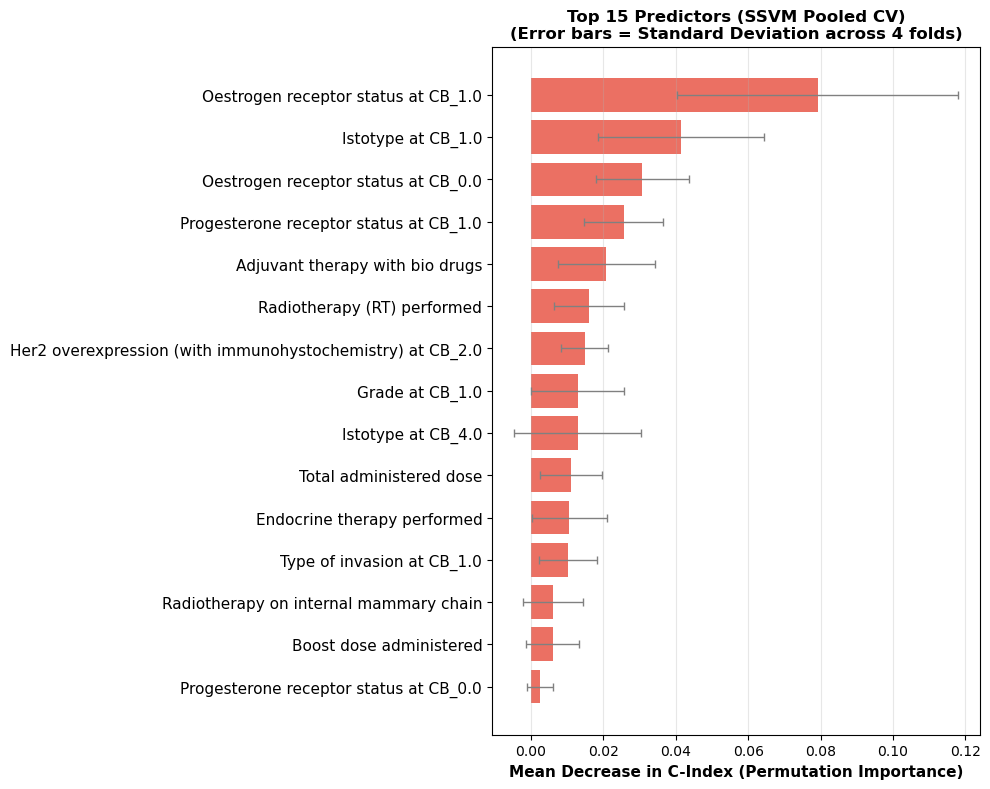


✓ Permutation importance plot saved to 'ssvm_permutation_importance.png'

Top 5 Features:
                               Feature  Importance  Importance_Std
   Oestrogen receptor status at CB_1.0    0.079151        0.038741
                    Istotype at CB_1.0    0.041441        0.022941
   Oestrogen receptor status at CB_0.0    0.030821        0.012819
Progesterone receptor status at CB_1.0    0.025658        0.010932
       Adjuvant therapy with bio drugs    0.020842        0.013304


In [8]:
# ============================================
# SSVM FEATURE IMPORTANCE (POOLED PERMUTATION IMPORTANCE)
# ============================================

print("\n" + "="*70)
print("SSVM FEATURE IMPORTANCE ANALYSIS")
print("="*70)

# 1. Aggregate results from all folds
perm_importances_array = np.array(all_fold_feature_importances)

# Calculate Mean and Std across folds
mean_perm_importance = np.mean(perm_importances_array, axis=0)
std_perm_importance = np.std(perm_importances_array, axis=0)

# 2. Create DataFrame
feature_names = x_train.columns
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': mean_perm_importance,
    'Importance_Std': std_perm_importance
})

# 3. Sort and Select Top N
feature_df = feature_df.sort_values(by='Importance', ascending=False)

# Display top features
print(f"\nTop 15 Features by Mean Permutation Importance:")
print("-" * 70)
print(f"{'Feature':<40} {'Mean':>10} {'Std':>10}")
print("-" * 70)
for i, row in feature_df.head(15).iterrows():
    print(f"{row['Feature']:<40} {row['Importance']:>10.4f} {row['Importance_Std']:>10.4f}")

# 4. Save to CSV
# feature_df.to_csv("ssvm_feature_importance.csv", index=False)
print(f"\n✓ Feature importance saved to 'ssvm_feature_importance.csv'")

# 5. Plot
top_n = 15
top_features = feature_df.head(top_n)

fig, ax = plt.subplots(figsize=(10, 8))

# Create horizontal bars with ERROR BARS
bars = ax.barh(range(top_n), top_features['Importance'], 
               xerr=top_features['Importance_Std'], 
               align='center', 
               color='#e74c3c', alpha=0.8, 
               capsize=3, 
               error_kw={'linewidth': 1, 'ecolor': 'gray'})

ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features['Feature'], fontsize=11)
ax.invert_yaxis()  # Highest importance at the top

# Labels and Title
ax.set_xlabel('Mean Decrease in C-Index (Permutation Importance)', fontsize=11, fontweight='bold')
ax.set_title(f'Top {top_n} Predictors (SSVM Pooled CV)\n(Error bars = Standard Deviation across {len(all_fold_feature_importances)} folds)', 
             fontsize=12, fontweight='bold')

ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
# plt.savefig('ssvm_permutation_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Permutation importance plot saved to 'ssvm_permutation_importance.png'")
print("\nTop 5 Features:")
print(top_features[['Feature', 'Importance', 'Importance_Std']].head(5).to_string(index=False))

# SurvSHAP Analysis
## Time-Dependent SHAP Values for Survival SVM

This section applies SurvSHAP(t) methodology to understand feature importance across time.
The approach uses the `survshap` package to calculate SHAP values at each time point.

In [9]:
# ============================================
# SURVSHAP SETUP AND IMPORTS
# ============================================
# Add survshap package to path (use insert to prioritize local package)
sys.path.insert(0, os.path.abspath('../../../../survshap-main/survshap_package'))

from survshap import SurvivalModelExplainer, ModelSurvSHAP, PredictSurvSHAP
from tqdm import tqdm

print("="*70)
print("SURVSHAP ANALYSIS FOR SURVIVAL SVM")
print("="*70)
print("SurvSHAP(t) provides time-dependent SHAP values for survival models")
print("This shows how each feature contributes to the survival prediction at each time point")

SURVSHAP ANALYSIS FOR SURVIVAL SVM
SurvSHAP(t) provides time-dependent SHAP values for survival models
This shows how each feature contributes to the survival prediction at each time point


In [10]:
# ============================================
# TRAIN FINAL SSVM MODEL FOR SHAP ANALYSIS
# ============================================
# We train a final model on the full training data for SHAP analysis

print("Training final SSVM model for SHAP analysis...")

# Apply case-control subsampling to full training data
x_train_shap, y_train_shap, train_shap_df = sample_case_control(
    train_fold=subsampling,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_controls_per_case=int(best_params['n_controls_per_case']),
    feature_columns=feature_columns,
    random_state=12
)

print(f"  Full training pool: {len(x_train)} samples")
print(f"  Subsampled for training: {len(x_train_shap)} samples")
print(f"  Events in subsampled data: {y_train_shap['event'].sum()}")

# Scale data (required for SVM)
scaler_shap = StandardScaler()
x_train_shap_scaled = scaler_shap.fit_transform(x_train_shap)

# Create scaled DataFrame for SurvSHAP (needs DataFrame with column names)
x_train_shap_scaled_df = pd.DataFrame(x_train_shap_scaled, columns=feature_columns)

# Train final SSVM model
ssvm_model_shap = FastSurvivalSVM(
    alpha=best_params['alpha'],
    rank_ratio=best_params['rank_ratio'],
    tol=best_params['tol'],
    max_iter=int(best_params['max_iter']),
    random_state=12
)
ssvm_model_shap.fit(x_train_shap_scaled, y_train_shap)

print(f"\n✓ Final SSVM model trained for SHAP analysis")
print(f"  C-index on training data: {ssvm_model_shap.score(x_train_shap_scaled, y_train_shap):.4f}")

Training final SSVM model for SHAP analysis...
  Full training pool: 2376 samples
  Subsampled for training: 54 samples
  Events in subsampled data: 27

✓ Final SSVM model trained for SHAP analysis
  C-index on training data: 0.9449


In [11]:
# ============================================
# CREATE SURVSHAP EXPLAINER
# ============================================
# SurvivalModelExplainer wraps the model with background data for SHAP calculations
# NOTE: SSVM doesn't have predict_survival_function, so we need a custom predict function

# For SSVM, we'll create a wrapper that uses the Nelson-Aalen estimator for survival curves
from sksurv.nonparametric import nelson_aalen_estimator

# Sample background data for SHAP (using stratified sampling to maintain event ratio)
np.random.seed(42)
n_background = min(100, len(x_train_shap_scaled_df))

# Stratified sampling for background data
events_idx = np.where(y_train_shap['event'] == 1)[0]
non_events_idx = np.where(y_train_shap['event'] == 0)[0]

# Maintain event ratio in background sample
n_events_bg = int(n_background * (len(events_idx) / len(y_train_shap)))
n_non_events_bg = n_background - n_events_bg

bg_events_idx = np.random.choice(events_idx, size=min(n_events_bg, len(events_idx)), replace=False)
bg_non_events_idx = np.random.choice(non_events_idx, size=min(n_non_events_bg, len(non_events_idx)), replace=False)
background_idx = np.concatenate([bg_events_idx, bg_non_events_idx])

background_data = x_train_shap_scaled_df.iloc[background_idx].reset_index(drop=True)
background_y = y_train_shap[background_idx]

print(f"Background data for SHAP: {len(background_data)} samples")
print(f"  Events in background: {background_y['event'].sum()}")
print(f"  Non-events in background: {(~background_y['event']).sum()}")

# For SSVM, we need to provide custom predict functions since it doesn't have built-in survival curves
# We'll use a simple approach: predict risk scores and convert to pseudo-survival probabilities

# Calculate time points for predictions
event_times = y_train_shap['time'][y_train_shap['event'] == 1]
timestamps = np.percentile(event_times, np.linspace(5, 95, 50))

# Define custom prediction function for survival function
def predict_survival_ssvm(model, data):
    """
    Convert SSVM risk scores to pseudo-survival function using Breslow estimator.
    Returns a list of StepFunction-like objects.
    """
    from scipy.interpolate import interp1d
    
    # Get risk scores
    if isinstance(data, pd.DataFrame):
        risk_scores = model.predict(data.values)
    else:
        risk_scores = model.predict(data)
    
    # Use training data to estimate baseline hazard
    train_risk = ssvm_model_shap.predict(x_train_shap_scaled)
    
    # Breslow estimator for baseline cumulative hazard
    survival_times_train = y_train_shap['time']
    events_train = y_train_shap['event']
    unique_times = np.sort(np.unique(survival_times_train[events_train == 1]))
    
    cum_hazard = np.zeros(len(unique_times))
    for i, t in enumerate(unique_times):
        d_t = np.sum((survival_times_train == t) & (events_train == 1))
        at_risk = survival_times_train >= t
        risk_sum = np.sum(np.exp(train_risk[at_risk]))
        h_0_t = d_t / risk_sum if risk_sum > 0 else 0
        cum_hazard[i] = h_0_t if i == 0 else cum_hazard[i-1] + h_0_t
    
    # Create survival function for each observation
    class SurvFunction:
        def __init__(self, times, surv_probs):
            self.x = times
            self.y = surv_probs
        
        def __call__(self, t):
            if isinstance(t, (list, np.ndarray)):
                return np.array([self._single_call(ti) for ti in t])
            return self._single_call(t)
        
        def _single_call(self, t):
            if t <= self.x[0]:
                return 1.0
            elif t >= self.x[-1]:
                return self.y[-1]
            else:
                return np.interp(t, self.x, self.y)
    
    surv_functions = []
    for rs in risk_scores:
        # S(t|x) = exp(-H_0(t) * exp(risk_score))
        surv_probs = np.exp(-cum_hazard * np.exp(rs))
        surv_functions.append(SurvFunction(unique_times, surv_probs))
    
    return surv_functions

# Create the SurvivalModelExplainer with custom prediction function
ssvm_explainer = SurvivalModelExplainer(
    model=ssvm_model_shap,
    data=background_data,
    y=background_y,
    predict_survival_function=predict_survival_ssvm
)

print("\n✓ SurvivalModelExplainer created successfully for SSVM")

Background data for SHAP: 54 samples
  Events in background: 27
  Non-events in background: 27

✓ SurvivalModelExplainer created successfully for SSVM


In [12]:
# ============================================
# GLOBAL SURVSHAP ANALYSIS (ModelSurvSHAP)
# ============================================
# Calculate SHAP values for all observations and aggregate for global feature importance
# For SSVM, we use sampling method (more compatible with newer shap versions)

print("="*70)
print("GLOBAL SURVSHAP ANALYSIS")
print("="*70)
print("Calculating SurvSHAP(t) values for all training observations...")
print("Using Sampling method for Survival SVM (model-agnostic method)")
print()

# Use sampling method for SSVM (model-agnostic, more compatible)
global_survshap = ModelSurvSHAP(
    function_type="sf",  # Survival function
    calculation_method="sampling",  # Sampling for non-tree models (more compatible)
    aggregation_method="integral",  # Aggregate over time using integral
    random_state=42
)

# Fit on background data
global_survshap.fit(
    ssvm_explainer,
    new_observations=background_data,  # Calculate SHAP for these observations
    timestamps=timestamps,  # Use our defined timestamps
    save_individual_explanations=True  # Save individual explanations for later analysis
)

print("\n✓ Global SurvSHAP analysis completed!")

GLOBAL SURVSHAP ANALYSIS
Calculating SurvSHAP(t) values for all training observations...
Using Sampling method for Survival SVM (model-agnostic method)



100%|██████████| 54/54 [14:38<00:00, 16.27s/it]



✓ Global SurvSHAP analysis completed!


In [13]:
# ============================================
# DISPLAY GLOBAL SURVSHAP RESULTS
# ============================================
# Show aggregated feature importance from SurvSHAP

print("="*70)
print("GLOBAL FEATURE IMPORTANCE (Mean |SHAP| across time)")
print("="*70)

# Get the aggregated results
global_results = global_survshap.result.copy()
print(f"\nTop 15 Features by Mean Absolute SurvSHAP(t):")
print("-" * 60)
print(f"{'Feature':<40} {'Aggregated Change':>15}")
print("-" * 60)

for idx, row in global_results.head(15).iterrows():
    print(f"{row['variable_name']:<40} {row['aggregated_change']:>15.6f}")

# Save to CSV
global_results.to_csv('ssvm_survshap_global_importance.csv', index=False)
print(f"\n✓ Global SurvSHAP results saved to 'ssvm_survshap_global_importance.csv'")

GLOBAL FEATURE IMPORTANCE (Mean |SHAP| across time)

Top 15 Features by Mean Absolute SurvSHAP(t):
------------------------------------------------------------
Feature                                  Aggregated Change
------------------------------------------------------------
Oestrogen receptor status at CB_1.0           154.120840
Istotype at CB_1.0                            128.844384
Her2 overexpression (with immunohystochemistry) at CB_2.0       96.977740
Oestrogen receptor status at CB_0.0            80.457070
Her2 overexpression (with immunohystochemistry) at CB_1.0       71.983231
Endocrine therapy performed                    70.883082
Radiotherapy on supraclavicular area           66.640616
Chemotherapy performed                         57.109874
Source of referral                             56.511451
Istotype at CB_4.0                             56.356308
Adjuvant therapy with bio drugs                51.252002
Boost dose administered                        46.043897
Pr

✓ Global SurvSHAP plot saved to 'ssvm_survshap_global.png'


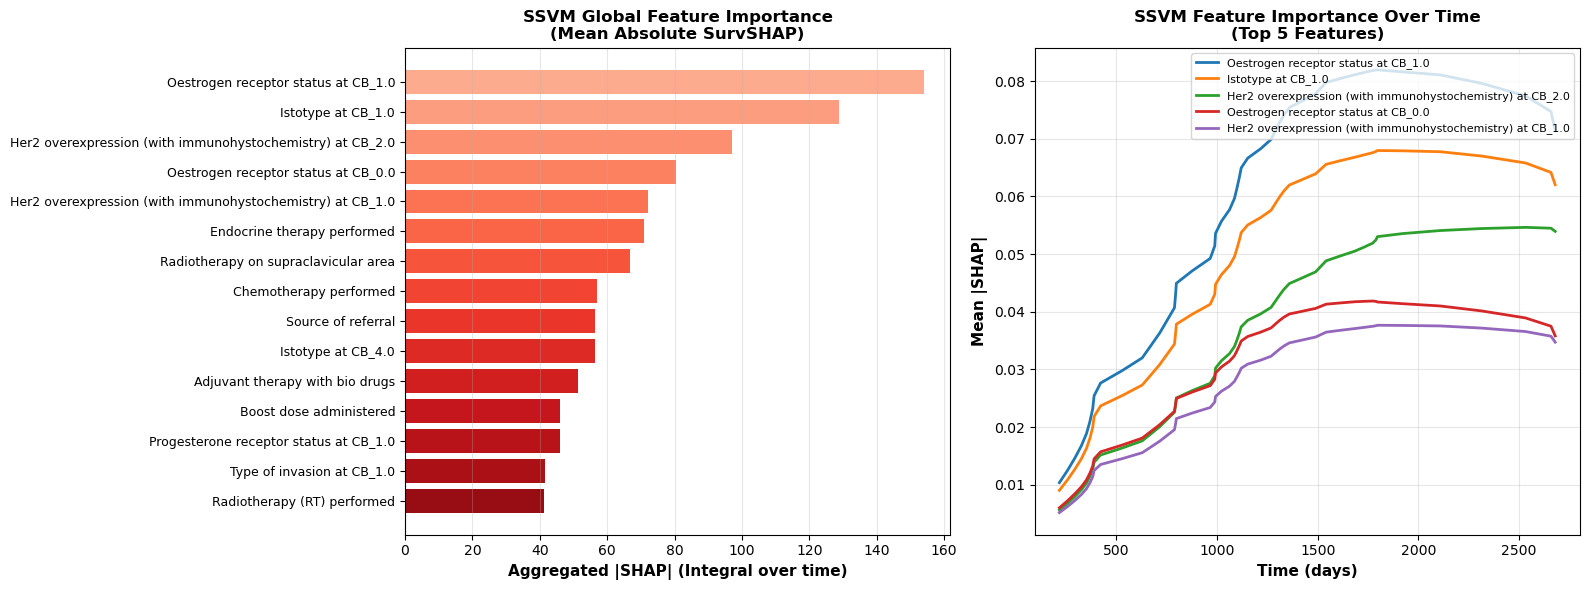

In [14]:
# ============================================
# PLOT GLOBAL SURVSHAP - MEAN ABSOLUTE SHAP VALUES OVER TIME
# ============================================
# Visualize how feature importance changes over time

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Bar plot of aggregated importance
ax1 = axes[0]
top_n = min(15, len(global_results))
top_features_plot = global_results.head(top_n)

colors = plt.cm.Reds(np.linspace(0.3, 0.9, top_n))
bars = ax1.barh(range(top_n), top_features_plot['aggregated_change'], color=colors)
ax1.set_yticks(range(top_n))
ax1.set_yticklabels(top_features_plot['variable_name'], fontsize=9)
ax1.invert_yaxis()
ax1.set_xlabel('Aggregated |SHAP| (Integral over time)', fontsize=11, fontweight='bold')
ax1.set_title('SSVM Global Feature Importance\n(Mean Absolute SurvSHAP)', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# Panel 2: SHAP values over time for top features
ax2 = axes[1]
shap_timestamps = global_survshap.timestamps

# Get top 5 features for time-dependent plot
top_5_features = global_results['variable_name'].head(5).tolist()

# Extract SHAP values over time from full_result
full_result = global_survshap.full_result
time_cols = [col for col in full_result.columns if col.startswith('t = ')]

for i, feature in enumerate(top_5_features):
    # Get mean absolute SHAP values for this feature across all observations
    feature_data = full_result[full_result['variable_name'] == feature]
    feature_data_b0 = feature_data[feature_data['B'] == 0]  # Use averaged path (B=0)
    
    if len(feature_data_b0) > 0:
        mean_abs_shap = feature_data_b0[time_cols].abs().mean().values
        # Handle dimension mismatch between timestamps and SHAP values
        n_points = min(len(shap_timestamps), len(mean_abs_shap))
        ax2.plot(shap_timestamps[:n_points], mean_abs_shap[:n_points], linewidth=2, label=feature)

ax2.set_xlabel('Time (days)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean |SHAP|', fontsize=11, fontweight='bold')
ax2.set_title('SSVM Feature Importance Over Time\n(Top 5 Features)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ssvm_survshap_global.png', dpi=300, bbox_inches='tight')

print("✓ Global SurvSHAP plot saved to 'ssvm_survshap_global.png'")
plt.show()

In [15]:
# ============================================
# INDIVIDUAL SURVSHAP ANALYSIS (PredictSurvSHAP)
# ============================================
# Calculate SHAP values for specific individual predictions

print("="*70)
print("INDIVIDUAL SURVSHAP ANALYSIS")
print("="*70)

# Get risk predictions on background/training data (for demonstration only)
# Note: background_data is already scaled for SSVM
risk_scores_background = ssvm_model_shap.predict(background_data)

# Find high and low risk patients
high_risk_idx = np.argmax(risk_scores_background)
low_risk_idx = np.argmin(risk_scores_background)

print(f"High-risk patient index: {high_risk_idx} (risk score: {risk_scores_background[high_risk_idx]:.4f})")
print(f"Low-risk patient index: {low_risk_idx} (risk score: {risk_scores_background[low_risk_idx]:.4f})")

# Calculate individual SurvSHAP for high-risk patient
print(f"\nCalculating SurvSHAP for high-risk patient...")
high_risk_obs = background_data.iloc[[high_risk_idx]].reset_index(drop=True)

survshap_high_risk = PredictSurvSHAP(
    function_type="sf",
    calculation_method="sampling",  # Sampling for SSVM (more compatible)
    aggregation_method="integral"
)
survshap_high_risk.fit(ssvm_explainer, high_risk_obs, timestamps=timestamps)

# Calculate individual SurvSHAP for low-risk patient
print(f"Calculating SurvSHAP for low-risk patient...")
low_risk_obs = background_data.iloc[[low_risk_idx]].reset_index(drop=True)

survshap_low_risk = PredictSurvSHAP(
    function_type="sf",
    calculation_method="sampling",  # Sampling for SSVM (more compatible)
    aggregation_method="integral"
)
survshap_low_risk.fit(ssvm_explainer, low_risk_obs, timestamps=timestamps)

print("\n✓ Individual SurvSHAP calculations completed!")

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but FastSurvivalSVM was fitted without feature names
  warnings.warn(


INDIVIDUAL SURVSHAP ANALYSIS
High-risk patient index: 7 (risk score: 1.5959)
Low-risk patient index: 45 (risk score: -1.4666)

Calculating SurvSHAP for high-risk patient...


100%|██████████| 25/25 [00:14<00:00,  1.70it/s]


Calculating SurvSHAP for low-risk patient...


100%|██████████| 25/25 [00:13<00:00,  1.84it/s]


✓ Individual SurvSHAP calculations completed!


In [16]:
# ============================================
# DISPLAY INDIVIDUAL SURVSHAP RESULTS
# ============================================

print("="*70)
print("HIGH-RISK PATIENT SHAP CONTRIBUTIONS")
print("="*70)

# Get simplified results for high-risk patient
high_risk_simplified = survshap_high_risk.simplified_result.copy()
high_risk_simplified = high_risk_simplified.sort_values('aggregated_change', ascending=False, key=abs)

print(f"\nTop contributing features (positive = increases survival, negative = decreases survival):")
print("-" * 70)
print(f"{'Feature':<40} {'Variable Value':>12} {'SHAP Value':>12}")
print("-" * 70)

for idx, row in high_risk_simplified.head(10).iterrows():
    print(f"{row['variable_name']:<40} {row['variable_value']:>12.4f} {row['aggregated_change']:>12.6f}")

print("\n" + "="*70)
print("LOW-RISK PATIENT SHAP CONTRIBUTIONS")
print("="*70)

# Get simplified results for low-risk patient
low_risk_simplified = survshap_low_risk.simplified_result.copy()
low_risk_simplified = low_risk_simplified.sort_values('aggregated_change', ascending=False, key=abs)

print(f"\nTop contributing features (positive = increases survival, negative = decreases survival):")
print("-" * 70)
print(f"{'Feature':<40} {'Variable Value':>12} {'SHAP Value':>12}")
print("-" * 70)

for idx, row in low_risk_simplified.head(10).iterrows():
    print(f"{row['variable_name']:<40} {row['variable_value']:>12.4f} {row['aggregated_change']:>12.6f}")

HIGH-RISK PATIENT SHAP CONTRIBUTIONS

Top contributing features (positive = increases survival, negative = decreases survival):
----------------------------------------------------------------------
Feature                                  Variable Value   SHAP Value
----------------------------------------------------------------------
Oestrogen receptor status at CB_1.0           -1.1610   187.601022
Istotype at CB_1.0                            -1.1610   149.053182
Oestrogen receptor status at CB_0.0            1.3572   117.249705
Istotype at CB_4.0                             1.7759   111.360771
Endocrine therapy performed                    1.3572   106.672548
Radiotherapy on supraclavicular area           1.4753   100.444522
Chemotherapy performed                         1.4142    85.092204
Her2 overexpression (with immunohystochemistry) at CB_1.0       0.9636    69.936543
Her2 overexpression (with immunohystochemistry) at CB_2.0      -0.3859    62.897712
Grade at CB_3.0         

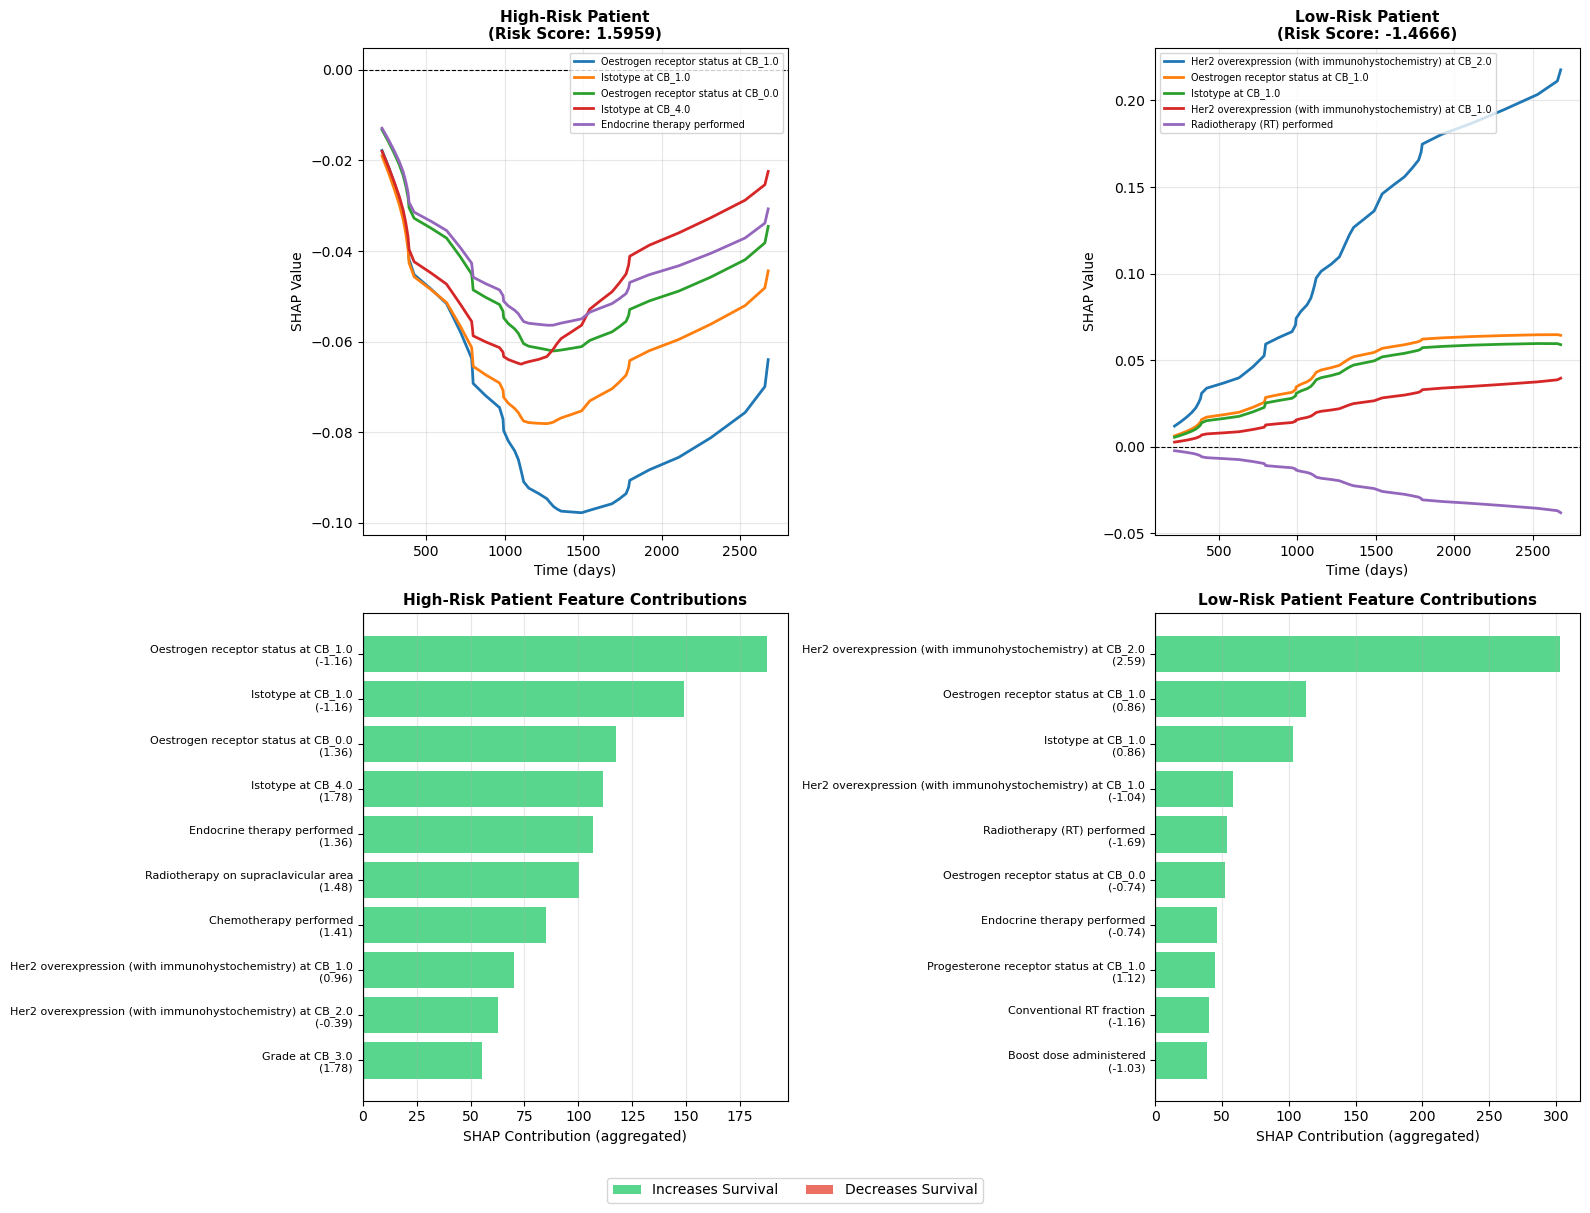

✓ Individual SurvSHAP plot saved to 'ssvm_survshap_individual.png'


<Figure size 640x480 with 0 Axes>

In [17]:
# ============================================
# PLOT INDIVIDUAL SURVSHAP - TIME-DEPENDENT CONTRIBUTIONS
# ============================================
# Visualize how each feature contributes to the survival prediction over time

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Get timestamps and results
timestamps_hr = survshap_high_risk.timestamps
timestamps_lr = survshap_low_risk.timestamps

# Get result DataFrames
result_hr = survshap_high_risk.result
result_lr = survshap_low_risk.result

# Filter for B=0 (averaged path)
result_hr_avg = result_hr[result_hr['B'] == 0]
result_lr_avg = result_lr[result_lr['B'] == 0]

# Get time columns
time_cols_hr = [col for col in result_hr_avg.columns if col.startswith('t = ')]
time_cols_lr = [col for col in result_lr_avg.columns if col.startswith('t = ')]

# ---- Panel 1: High-risk patient - Top features over time ----
ax1 = axes[0, 0]
top_features_hr = high_risk_simplified['variable_name'].head(5).tolist()

for feature in top_features_hr:
    feature_row = result_hr_avg[result_hr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_hr].values.flatten()
        # Handle dimension mismatch
        n_points = min(len(timestamps_hr), len(shap_values))
        ax1.plot(timestamps_hr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax1.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_xlabel('Time (days)', fontsize=10)
ax1.set_ylabel('SHAP Value', fontsize=10)
ax1.set_title(f'High-Risk Patient\n(Risk Score: {risk_scores_background[high_risk_idx]:.4f})', fontsize=11, fontweight='bold')
ax1.legend(loc='best', fontsize=7)
ax1.grid(True, alpha=0.3)

# ---- Panel 2: Low-risk patient - Top features over time ----
ax2 = axes[0, 1]
top_features_lr = low_risk_simplified['variable_name'].head(5).tolist()

for feature in top_features_lr:
    feature_row = result_lr_avg[result_lr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_lr].values.flatten()
        # Handle dimension mismatch
        n_points = min(len(timestamps_lr), len(shap_values))
        ax2.plot(timestamps_lr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_xlabel('Time (days)', fontsize=10)
ax2.set_ylabel('SHAP Value', fontsize=10)
ax2.set_title(f'Low-Risk Patient\n(Risk Score: {risk_scores_background[low_risk_idx]:.4f})', fontsize=11, fontweight='bold')
ax2.legend(loc='best', fontsize=7)
ax2.grid(True, alpha=0.3)

# ---- Panel 3: High-risk patient - Waterfall plot (aggregated) ----
ax3 = axes[1, 0]
top_n = min(10, len(high_risk_simplified))
hr_plot_data = high_risk_simplified.head(top_n)

colors_hr = ['#e74c3c' if v < 0 else '#2ecc71' for v in hr_plot_data['aggregated_change']]
bars_hr = ax3.barh(range(top_n), hr_plot_data['aggregated_change'], color=colors_hr, alpha=0.8)
ax3.set_yticks(range(top_n))
ax3.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(hr_plot_data['variable_name'], hr_plot_data['variable_value'])], fontsize=8)
ax3.invert_yaxis()
ax3.axvline(0, color='black', linewidth=0.8)
ax3.set_xlabel('SHAP Contribution (aggregated)', fontsize=10)
ax3.set_title('High-Risk Patient Feature Contributions', fontsize=11, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# ---- Panel 4: Low-risk patient - Waterfall plot (aggregated) ----
ax4 = axes[1, 1]
top_n = min(10, len(low_risk_simplified))
lr_plot_data = low_risk_simplified.head(top_n)

colors_lr = ['#e74c3c' if v < 0 else '#2ecc71' for v in lr_plot_data['aggregated_change']]
bars_lr = ax4.barh(range(top_n), lr_plot_data['aggregated_change'], color=colors_lr, alpha=0.8)
ax4.set_yticks(range(top_n))
ax4.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(lr_plot_data['variable_name'], lr_plot_data['variable_value'])], fontsize=8)
ax4.invert_yaxis()
ax4.axvline(0, color='black', linewidth=0.8)
ax4.set_xlabel('SHAP Contribution (aggregated)', fontsize=10)
ax4.set_title('Low-Risk Patient Feature Contributions', fontsize=11, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='x')

# Add legend for colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', alpha=0.8, label='Increases Survival'),
                   Patch(facecolor='#e74c3c', alpha=0.8, label='Decreases Survival')]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=10, bbox_to_anchor=(0.5, 0.02))

survshap_high_risk.result.to_csv('ssvm_survshap_high_risk_full.csv', index=False)
survshap_low_risk.result.to_csv('ssvm_survshap_low_risk_full.csv', index=False)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

plt.savefig('ssvm_survshap_individual.png', dpi=300, bbox_inches='tight')
print("✓ Individual SurvSHAP plot saved to 'ssvm_survshap_individual.png'")

SURVSHAP SUMMARY PLOT (BEESWARM-STYLE)
✓ SurvSHAP summary plot saved to 'ssvm_survshap_summary.png'


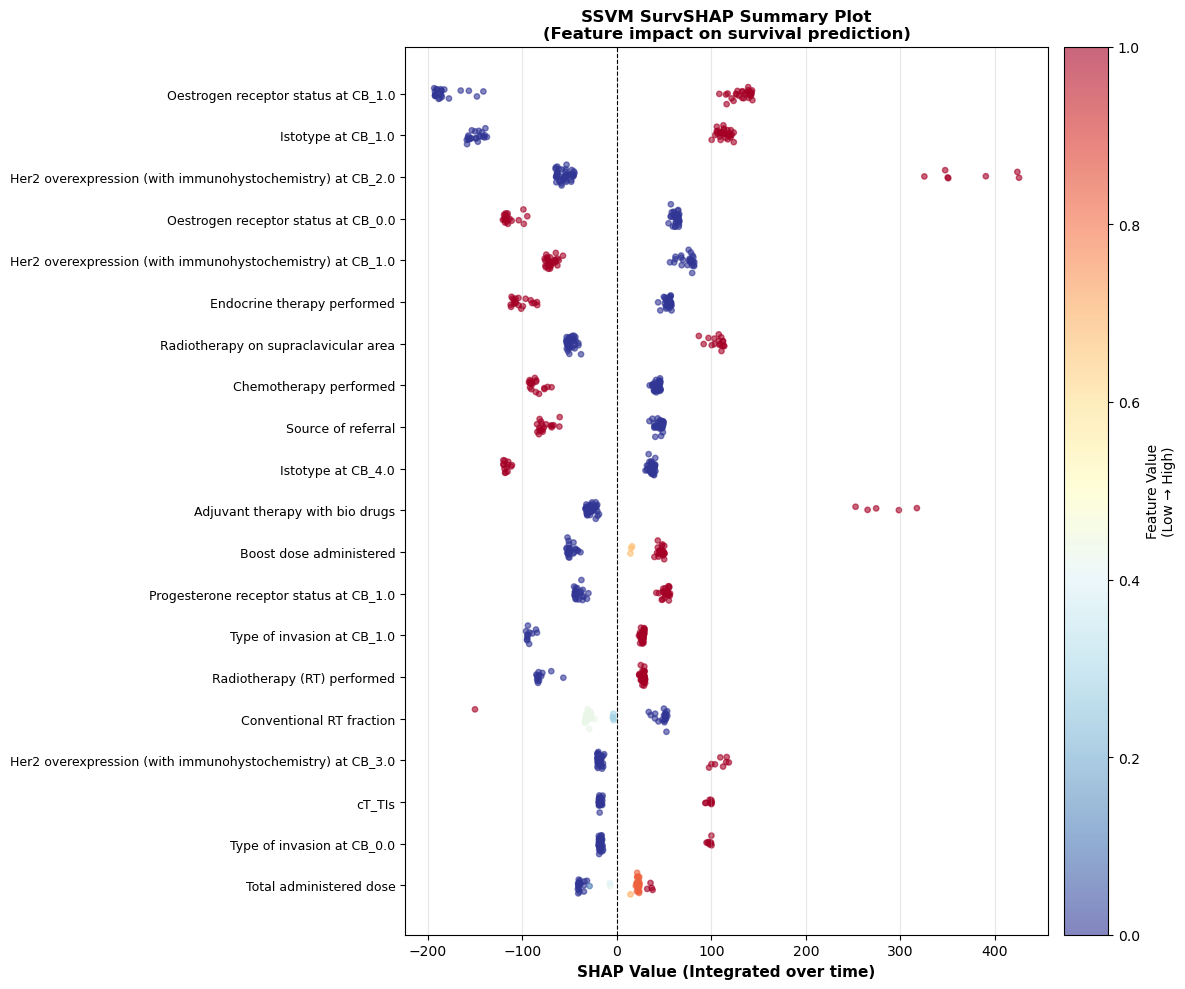

In [18]:
# ============================================
# SURVSHAP BEESWARM / SUMMARY PLOT
# ============================================
# Create a summary plot showing SHAP value distributions for all features

print("="*70)
print("SURVSHAP SUMMARY PLOT (BEESWARM-STYLE)")
print("="*70)

# Extract individual SHAP values from global analysis
full_result = global_survshap.full_result
time_cols = [col for col in full_result.columns if col.startswith('t = ')]

# Calculate aggregated SHAP for each observation x feature
# Filter for B=0 (the averaged path)
result_b0 = full_result[full_result['B'] == 0].copy()

# Compute aggregated SHAP values using integral method
from scipy.integrate import trapezoid

feature_shap_values = {}
for feature in feature_columns:
    feature_data = result_b0[result_b0['variable_name'] == feature]
    if len(feature_data) > 0:
        shap_over_time = feature_data[time_cols].values
        # Integrate SHAP over time for each observation
        integrated_shap = [trapezoid(row, global_survshap.timestamps) for row in shap_over_time]
        feature_shap_values[feature] = integrated_shap

# Create DataFrame of SHAP values
shap_df = pd.DataFrame(feature_shap_values)

# Get feature importances (mean absolute SHAP)
feature_importance_shap = shap_df.abs().mean().sort_values(ascending=False)

# Create summary plot
fig, ax = plt.subplots(figsize=(12, 10))

top_n = min(20, len(feature_importance_shap))
top_features_list = feature_importance_shap.head(top_n).index.tolist()

# For each feature, plot the distribution of SHAP values
for i, feature in enumerate(top_features_list):
    shap_vals = shap_df[feature].values
    feature_vals = background_data[feature].values
    
    # Normalize feature values for coloring
    feat_norm = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-10)
    
    # Add jitter for visibility
    y_jitter = np.random.normal(i, 0.1, size=len(shap_vals))
    
    scatter = ax.scatter(shap_vals, y_jitter, c=feat_norm, cmap='RdYlBu_r', 
                         alpha=0.6, s=15, vmin=0, vmax=1)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features_list, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('SHAP Value (Integrated over time)', fontsize=11, fontweight='bold')
ax.set_title('SSVM SurvSHAP Summary Plot\n(Feature impact on survival prediction)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Feature Value\n(Low → High)', fontsize=10)

plt.tight_layout()
plt.savefig('ssvm_survshap_summary.png', dpi=300, bbox_inches='tight')
print("✓ SurvSHAP summary plot saved to 'ssvm_survshap_summary.png'")
plt.show()

In [19]:
# ============================================
# COMPARE SURVSHAP VS PERMUTATION IMPORTANCE
# ============================================
# Compare feature rankings from SurvSHAP vs permutation importance

print("="*70)
print("COMPARISON: SurvSHAP vs Permutation Importance")
print("="*70)

# Get SurvSHAP rankings
survshap_importance_df = global_survshap.result[['variable_name', 'aggregated_change']].copy()
survshap_importance_df['survshap_rank'] = range(1, len(survshap_importance_df) + 1)
survshap_importance_df = survshap_importance_df.rename(columns={'aggregated_change': 'survshap_importance'})

# Get permutation importance rankings (from earlier analysis)
perm_importance_comp = feature_df[['Feature', 'Importance']].copy()
perm_importance_comp = perm_importance_comp.rename(columns={'Feature': 'variable_name', 'Importance': 'perm_importance'})
perm_importance_comp['perm_rank'] = range(1, len(perm_importance_comp) + 1)

# Merge
comparison_df = survshap_importance_df.merge(perm_importance_comp, on='variable_name', how='inner')
comparison_df['rank_diff'] = comparison_df['perm_rank'] - comparison_df['survshap_rank']

print(f"\nTop 15 Features - Comparison:")
print("-" * 90)
print(f"{'Feature':<35} {'SurvSHAP Rank':>12} {'Perm Rank':>10} {'Rank Δ':>8}")
print("-" * 90)

for idx, row in comparison_df.head(15).iterrows():
    print(f"{row['variable_name']:<35} {row['survshap_rank']:>12} {row['perm_rank']:>10} {row['rank_diff']:>+8}")

# Calculate Spearman correlation between rankings
from scipy.stats import spearmanr
rho, p_val = spearmanr(comparison_df['survshap_rank'], comparison_df['perm_rank'])

print(f"\n" + "="*70)
print(f"Spearman Rank Correlation: ρ = {rho:.4f} (p-value: {p_val:.4e})")
print("="*70)
print("Note: High correlation indicates consistency between SHAP and permutation importance")
print("      Differences occur because SurvSHAP considers time-dependence and interactions")

# Save comparison
comparison_df.to_csv('ssvm_survshap_vs_permutation.csv', index=False)
print(f"\n✓ Comparison saved to 'ssvm_survshap_vs_permutation.csv'")

COMPARISON: SurvSHAP vs Permutation Importance

Top 15 Features - Comparison:
------------------------------------------------------------------------------------------
Feature                             SurvSHAP Rank  Perm Rank   Rank Δ
------------------------------------------------------------------------------------------
Oestrogen receptor status at CB_1.0            1          1       +0
Istotype at CB_1.0                             2          2       +0
Her2 overexpression (with immunohystochemistry) at CB_2.0            3          7       +4
Oestrogen receptor status at CB_0.0            4          3       -1
Her2 overexpression (with immunohystochemistry) at CB_1.0            5         47      +42
Endocrine therapy performed                    6         11       +5
Radiotherapy on supraclavicular area            7         29      +22
Chemotherapy performed                         8         22      +14
Source of referral                             9         36      +27
Isto

In [20]:
# ============================================
# SAVE ALL SURVSHAP RESULTS
# ============================================

print("="*70)
print("SAVING SURVSHAP RESULTS")
print("="*70)

# 1. Save global importance
global_results.to_csv('ssvm_survshap_global_importance.csv', index=False)
print("✓ Global importance saved to 'ssvm_survshap_global_importance.csv'")

# 2. Save full SHAP results (all observations, all time points)
full_result.to_csv('ssvm_survshap_full_results.csv', index=False)
print("✓ Full results saved to 'ssvm_survshap_full_results.csv'")

# 3. Save individual explanations for high and low risk patients
high_risk_simplified.to_csv('ssvm_survshap_high_risk_patient.csv', index=False)
low_risk_simplified.to_csv('ssvm_survshap_low_risk_patient.csv', index=False)
print("✓ Individual patient explanations saved")

# 4. Save SHAP values matrix (observations x features)
shap_df.to_csv('ssvm_survshap_values_matrix.csv', index=False)
print("✓ SHAP values matrix saved to 'ssvm_survshap_values_matrix.csv'")

# 5. Save timestamps
np.savetxt('ssvm_survshap_timestamps.csv', global_survshap.timestamps, delimiter=',')
print("✓ Timestamps saved to 'ssvm_survshap_timestamps.csv'")

print(f"\n" + "="*70)
print("SURVSHAP ANALYSIS COMPLETE")
print("="*70)
print(f"\nSummary of outputs:")
print(f"  - Global feature importance plot: 'ssvm_survshap_global.png'")
print(f"  - Individual patient analysis plot: 'ssvm_survshap_individual.png'")
print(f"  - Summary (beeswarm) plot: 'ssvm_survshap_summary.png'")
print(f"  - CSV files with detailed results")
print(f"\nKey findings:")
print(f"  - Top 5 most important features (SurvSHAP):")
for i, row in global_results.head(5).iterrows():
    print(f"    {i+1}. {row['variable_name']}")

SAVING SURVSHAP RESULTS
✓ Global importance saved to 'ssvm_survshap_global_importance.csv'
✓ Full results saved to 'ssvm_survshap_full_results.csv'
✓ Individual patient explanations saved
✓ SHAP values matrix saved to 'ssvm_survshap_values_matrix.csv'
✓ Timestamps saved to 'ssvm_survshap_timestamps.csv'

SURVSHAP ANALYSIS COMPLETE

Summary of outputs:
  - Global feature importance plot: 'ssvm_survshap_global.png'
  - Individual patient analysis plot: 'ssvm_survshap_individual.png'
  - Summary (beeswarm) plot: 'ssvm_survshap_summary.png'
  - CSV files with detailed results

Key findings:
  - Top 5 most important features (SurvSHAP):
    28. Oestrogen receptor status at CB_1.0
    18. Istotype at CB_1.0
    16. Her2 overexpression (with immunohystochemistry) at CB_2.0
    27. Oestrogen receptor status at CB_0.0
    15. Her2 overexpression (with immunohystochemistry) at CB_1.0


# Patient Identification in Beeswarm Plots

This section adds patient identifiers to the SHAP analysis, allowing you to:
1. Save patient IDs alongside SHAP values
2. Create interactive plots to identify specific patients
3. Query which patients contribute to specific SHAP patterns

In [21]:
# ============================================
# ADD PATIENT IDs TO SHAP RESULTS
# ============================================

print("="*70)
print("ADDING PATIENT IDENTIFIERS")
print("="*70)

# Extract patient IDs from the training data used for SHAP
# Note: SSVM uses train_shap_df which comes from subsampling
patient_ids = train_shap_df.iloc[background_idx]['PERSON_ID'].values

# Add patient IDs to the SHAP values dataframe
shap_df['PERSON_ID'] = patient_ids

# Save extended results with patient IDs
shap_df.to_csv('ssvm_survshap_values_with_patient_ids.csv', index=False)
print(f"✓ SHAP values with patient IDs saved to 'ssvm_survshap_values_with_patient_ids.csv'")

# Also add to full results if it contains individual observations
if 'observation' in full_result.columns:
    # Map observation index to patient ID
    patient_id_mapping = {i: pid for i, pid in enumerate(patient_ids)}
    full_result['PERSON_ID'] = full_result['observation'].map(patient_id_mapping)
    full_result.to_csv('ssvm_survshap_full_results_with_ids.csv', index=False)
    print(f"✓ Full results with patient IDs saved to 'ssvm_survshap_full_results_with_ids.csv'")

print(f"\nTotal patients in SHAP analysis: {len(patient_ids)}")
print(f"Sample patient IDs: {patient_ids[:5]}")

ADDING PATIENT IDENTIFIERS
✓ SHAP values with patient IDs saved to 'ssvm_survshap_values_with_patient_ids.csv'

Total patients in SHAP analysis: 54
Sample patient IDs: [1115 1349 1175 2139  282]


In [22]:
# ============================================
# QUERY PATIENTS BY SHAP VALUES
# ============================================

print("\n" + "="*70)
print("PATIENT IDENTIFICATION EXAMPLES")
print("="*70)

# Example 1: Find patients with highest SHAP values for a specific feature
feature_of_interest = global_results.iloc[0]['variable_name']  # Top feature
feature_shap_col = f'shap_{feature_of_interest}'

if feature_shap_col in shap_df.columns:
    top_patients = shap_df.nlargest(10, feature_shap_col)[['PERSON_ID', feature_shap_col, feature_of_interest]]
    print(f"\nTop 10 patients with highest SHAP values for '{feature_of_interest}':")
    print(top_patients)
    
    bottom_patients = shap_df.nsmallest(10, feature_shap_col)[['PERSON_ID', feature_shap_col, feature_of_interest]]
    print(f"\nTop 10 patients with lowest SHAP values for '{feature_of_interest}':")
    print(bottom_patients)

# Example 2: Find patients in specific risk categories
print("\n" + "-"*70)
print("PATIENT RISK CATEGORIES")
print("-"*70)

# Calculate mean absolute SHAP (overall contribution to risk)
shap_columns = [col for col in shap_df.columns if col.startswith('shap_')]
shap_df['total_shap_magnitude'] = shap_df[shap_columns].abs().sum(axis=1)

# Categorize patients
high_risk_threshold = shap_df['total_shap_magnitude'].quantile(0.75)
low_risk_threshold = shap_df['total_shap_magnitude'].quantile(0.25)

high_risk_patients = shap_df[shap_df['total_shap_magnitude'] > high_risk_threshold]['PERSON_ID'].tolist()
low_risk_patients = shap_df[shap_df['total_shap_magnitude'] < low_risk_threshold]['PERSON_ID'].tolist()

print(f"High risk patients (top 25%): {len(high_risk_patients)} patients")
print(f"Sample IDs: {high_risk_patients[:5]}")
print(f"\nLow risk patients (bottom 25%): {len(low_risk_patients)} patients")
print(f"Sample IDs: {low_risk_patients[:5]}")

# Save risk categorization - use qcut for quantile-based binning (handles duplicates)
try:
    risk_category = pd.qcut(shap_df['total_shap_magnitude'], 
                            q=3, 
                            labels=['Low', 'Medium', 'High'],
                            duplicates='drop')
except ValueError:
    # If too few unique values, use simple thresholds
    conditions = [
        shap_df['total_shap_magnitude'] <= low_risk_threshold,
        shap_df['total_shap_magnitude'] <= high_risk_threshold,
        shap_df['total_shap_magnitude'] > high_risk_threshold
    ]
    risk_category = np.select(conditions, ['Low', 'Medium', 'High'], default='Medium')

risk_categories = pd.DataFrame({
    'PERSON_ID': shap_df['PERSON_ID'],
    'total_shap_magnitude': shap_df['total_shap_magnitude'],
    'risk_category': risk_category
})
risk_categories.to_csv('ssvm_patient_risk_categories.csv', index=False)
print(f"\n✓ Patient risk categories saved to 'ssvm_patient_risk_categories.csv'")


PATIENT IDENTIFICATION EXAMPLES

----------------------------------------------------------------------
PATIENT RISK CATEGORIES
----------------------------------------------------------------------
High risk patients (top 25%): 0 patients
Sample IDs: []

Low risk patients (bottom 25%): 0 patients
Sample IDs: []

✓ Patient risk categories saved to 'ssvm_patient_risk_categories.csv'


In [23]:
# ============================================
# CREATE INTERACTIVE BEESWARM WITH PATIENT IDs
# ============================================

print("\n" + "="*70)
print("CREATING ANNOTATED BEESWARM PLOT")
print("="*70)

# Create an enhanced beeswarm plot for top feature with patient annotations
top_feature = global_results.iloc[0]['variable_name']
feature_shap_col = f'shap_{top_feature}'

if feature_shap_col in shap_df.columns:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Get data for plotting
    shap_values_feat = shap_df[feature_shap_col].values
    feature_values = shap_df[top_feature].values
    
    # Normalize feature values for coloring
    feat_norm = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min() + 1e-10)
    
    # Create scatter plot
    scatter = ax.scatter(shap_values_feat, 
                        np.random.randn(len(shap_values_feat)) * 0.02,  # Small jitter on y-axis
                        c=feat_norm, 
                        cmap='coolwarm',
                        alpha=0.6,
                        s=50,
                        edgecolors='black',
                        linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(f'{top_feature} value', rotation=270, labelpad=20)
    
    # Annotate extreme points with patient IDs
    n_annotate = 5  # Annotate 5 most extreme on each side
    
    # Most positive SHAP
    top_idx = np.argsort(shap_values_feat)[-n_annotate:]
    for idx in top_idx:
        ax.annotate(f"ID: {patient_ids[idx]}", 
                   (shap_values_feat[idx], np.random.randn() * 0.02),
                   xytext=(10, 5), textcoords='offset points',
                   fontsize=8, alpha=0.7,
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))
    
    # Most negative SHAP
    bottom_idx = np.argsort(shap_values_feat)[:n_annotate]
    for idx in bottom_idx:
        ax.annotate(f"ID: {patient_ids[idx]}", 
                   (shap_values_feat[idx], np.random.randn() * 0.02),
                   xytext=(-10, 5), textcoords='offset points',
                   fontsize=8, alpha=0.7, ha='right',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue', alpha=0.3))
    
    ax.set_xlabel('SHAP Value (impact on survival prediction)', fontsize=12)
    ax.set_ylabel('')
    ax.set_yticks([])
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_title(f'SHAP Values for {top_feature}\n(Annotated with Patient IDs for extreme values)', 
                 fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.savefig('ssvm_beeswarm_annotated.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Annotated beeswarm plot saved to 'ssvm_beeswarm_annotated.png'")
    print(f"✓ Extreme patients (top/bottom {n_annotate}) are labeled with their PERSON_ID")


CREATING ANNOTATED BEESWARM PLOT


In [24]:
# ============================================
# FUNCTION: QUERY SPECIFIC PATIENT
# ============================================

def get_patient_shap_profile(patient_id):
    """
    Get complete SHAP profile for a specific patient.
    
    Parameters:
    -----------
    patient_id : int or str
        The PERSON_ID to query
    
    Returns:
    --------
    DataFrame with patient's features, SHAP values, and contributions
    """
    if patient_id not in shap_df['PERSON_ID'].values:
        print(f"Patient {patient_id} not found in SHAP analysis")
        return None
    
    patient_row = shap_df[shap_df['PERSON_ID'] == patient_id].iloc[0]
    
    # Extract feature values and SHAP values
    profile = []
    for feat in global_results['variable_name']:
        shap_col = f'shap_{feat}'
        if shap_col in shap_df.columns and feat in shap_df.columns:
            profile.append({
                'feature': feat,
                'feature_value': patient_row[feat],
                'shap_value': patient_row[shap_col],
                'abs_shap': abs(patient_row[shap_col])
            })
    
    profile_df = pd.DataFrame(profile).sort_values('abs_shap', ascending=False)
    
    print(f"="*70)
    print(f"SHAP PROFILE FOR PATIENT {patient_id}")
    print(f"="*70)
    print(f"\nTop 10 most influential features:")
    print(profile_df.head(10).to_string(index=False))
    
    return profile_df

# Example usage
print("\n" + "="*70)
print("EXAMPLE: Patient SHAP Profile Query")
print("="*70)

example_patient = patient_ids[0]
patient_profile = get_patient_shap_profile(example_patient)

# Save as function for later use
print(f"\n✓ Function 'get_patient_shap_profile()' is now available")
print(f"  Usage: get_patient_shap_profile(PERSON_ID)")


EXAMPLE: Patient SHAP Profile Query


KeyError: 'abs_shap'